Open in Google Colab: https://colab.research.google.com/github/ari-price/Defense-Financial-Analytics/blob/main/defense_contractors_analysis.ipynb

## 🚀 How to Run this Notebook
To ensure all statistical metrics and visualizations are dynamically generated with the freshest data from Yahoo Finance, please follow these simple steps upon opening the notebook:

1. Go to the top menu and select **Runtime**.
2. Click **Run all** (or press `Ctrl + F9` / `Cmd + F9`).

This sequentially installs dependencies, loads configuration variables (such as the target tickers), pulls active market data, and populates fresh analytical results.

# Defense Contractors: Risk & Return Analysis (2015–2024)
Statistical profile of five U.S. defense primes — Northrop Grumman, Lockheed Martin, RTX, Boeing, and General Dynamics — benchmarked against the S&P 500 (SPY). See README for context.

## Setup

In [11]:
%pip install yfinance

import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf

## Configuration

In [12]:
tickers=["NOC", "LMT", "RTX", "BA", "GD"]
benchmark="SPY"
vix_ticker="^VIX"
start="2015-01-01"
end="2024-12-31"
interval="1d"
windows=[20, 60]
ann=252
var_conf=0.95

## Data Retrieval

In [13]:
def fetch_data(tickers, start, end, interval):
    all_tickers=tickers + [benchmark]
    raw=yf.download(all_tickers, start=start, end=end, interval=interval, auto_adjust=True, group_by="ticker", threads=True)
    closes=pd.DataFrame({t:raw[t]["Close"] for t in all_tickers})
    volumes=pd.DataFrame({t: raw[t]["Volume"] for t in tickers})
    return closes.dropna(how="all"), volumes.dropna(how="all")

In [14]:
def fetch_vix(start, end):
    vix=yf.download(vix_ticker, start=start, end=end, auto_adjust=True)["Close"]
    vix.name="VIX"
    return vix.dropna()
def fetch_earnings(tickers, start, end):
    out={}
    for t in tickers:
        try:
            df=yf.Ticker(t).earnings_dates
            if df is None or df.empty:
                out[t]=pd.DatetimeIndex([])
                continue
            idx=df.index.tz_localize(None)
            mask=(idx >= pd.to_datetime(start)) & (idx <= pd.to_datetime(end))
            out[t]=idx[mask]
        except Exception:
            out[t]=pd.DatetimeIndex([])
    return out

## Analysis Functions

In [15]:
def get_returns(closes):
    return closes.pct_change().dropna()

def describe_returns(returns):
    rows=[]
    for t in returns.columns:
        r=returns[t].dropna()
        jb_stat, jb_p=stats.jarque_bera(r)
        rows.append({
            "ticker": t,
            "mean": r.mean(),
            "std": r.std(),
            "ann_vol": r.std() * np.sqrt(ann),
            "skew": stats.skew(r),
            "kurt": stats.kurtosis(r),
            "jb_p": jb_p,
            "normal": jb_p > 0.05,
            "min": r.min(),
            "max": r.max(),
        })
    return pd.DataFrame(rows).set_index("ticker").round(5)

In [16]:
def rank_fat_tails(summary):
    return summary[["kurt", "skew", "ann_vol", "normal"]].sort_values("kurt", ascending=False)

In [17]:
def rolling_stats(closes, returns, windows, cols):
    out={}
    for t in cols:
        df=pd.DataFrame(index=closes.index)
        df["close"]=closes[t]
        for w in windows:
            df[f"ma{w}"]=closes[t].rolling(w).mean()
            df[f"vol{w}"]=returns[t].rolling(w).std() * np.sqrt(ann)
        out[t]=df
    return out

In [18]:
def drawdown_stats(closes, cols):
    rows=[]
    curves={}
    for t in cols:
        cum=closes[t] / closes[t].iloc[0]
        running_max=cum.cummax()
        dd=cum / running_max - 1
        curves[t]=dd
        end_dt=dd.idxmin()
        start_dt=cum.loc[:end_dt].idxmax()
        recovered=cum.loc[end_dt:][cum.loc[end_dt:] >= running_max.loc[end_dt]]
        recovery_dt=recovered.index[0] if len(recovered) else None
        length=(end_dt - start_dt).days
        rows.append({
            "ticker": t,
            "max_dd": dd.min(),
            "peak_date": start_dt.date(),
            "trough_date": end_dt.date(),
            "days_to_trough": length,
            "recovered_by": recovery_dt.date() if recovery_dt is not None else "not recovered",
        })
    return pd.DataFrame(rows).set_index("ticker"), curves

In [19]:
def var_cvar(returns, conf, cols):
    rows=[]
    for t in cols:
        r=returns[t].dropna()
        hist_var=np.percentile(r, (1 - conf) * 100)
        hist_cvar=r[r <= hist_var].mean()
        mu, sigma=r.mean(), r.std()
        z=stats.norm.ppf(1 - conf)
        param_var=mu + z * sigma
        rows.append({
            "ticker": t,
            "hist_var": hist_var,
            "hist_cvar": hist_cvar,
            "param_var": param_var,})
    return pd.DataFrame(rows).set_index("ticker").round(5)

In [20]:
def autocorr_table(returns, cols, lags=10):
    rows=[]
    for t in cols:
        r=returns[t].dropna()
        r2=r ** 2
        row={"ticker": t}
        for lag in range(1, lags + 1):
            row[f"acf_ret_l{lag}"]=r.autocorr(lag)
            row[f"acf_sq_l{lag}"]=r2.autocorr(lag)
        rows.append(row)
    return pd.DataFrame(rows).set_index("ticker").round(4)


In [21]:
def rolling_corr_to_bench(returns, cols, benchmark, window=60):
    out={}
    for t in cols:
        out[t]=returns[t].rolling(window).corr(returns[benchmark])
    return pd.DataFrame(out)


def beta_table(returns, cols, benchmark):
    rows=[]
    b=returns[benchmark]
    for t in cols:
        r=returns[t]
        cov=np.cov(r, b)[0, 1]
        var_b=np.var(b)
        beta=cov / var_b
        alpha=r.mean() - beta * b.mean()
        corr=r.corr(b)
        rows.append({"ticker": t, "beta": beta, "alpha_daily": alpha, "corr_to_bench": corr})
    return pd.DataFrame(rows).set_index("ticker").round(4)

In [22]:
def volume_price_table(returns, volumes, cols):
    rows=[]
    for t in cols:
        v=volumes[t]
        vz=(v - v.rolling(20).mean()) / v.rolling(20).std()
        move=returns[t].abs()
        corr=vz.corr(move)
        spike_days=vz[vz > 2].index
        avg_move_on_spike=move.loc[move.index.intersection(spike_days)].mean()
        avg_move_normal=move.mean()
        rows.append({
            "ticker": t,
            "vol_spike_days": len(spike_days),
            "corr_volz_absret": corr,
            "avg_move_on_spike": avg_move_on_spike,
            "avg_move_normal": avg_move_normal,
        })
    return pd.DataFrame(rows).set_index("ticker").round(4)

In [23]:
def earnings_impact_table(returns, earnings, cols):
    rows=[]
    for t in cols:
        dates=earnings[t]
        r=returns[t].dropna()
        hit_days=[]
        for d in dates:
            nearest=r.index[r.index.get_indexer([d], method="nearest")]
            hit_days.extend(nearest)
        hit_days=pd.DatetimeIndex(hit_days).unique()
        on_earnings=r.loc[r.index.intersection(hit_days)].abs()
        other_days=r.loc[~r.index.isin(hit_days)].abs()
        rows.append({
            "ticker": t,
            "n_earnings_events": len(dates),
            "avg_abs_move_earnings_day": on_earnings.mean() if len(on_earnings) else np.nan,
            "avg_abs_move_other_days": other_days.mean(),
            "ratio": (on_earnings.mean() / other_days.mean()) if len(on_earnings) else np.nan,})
    return pd.DataFrame(rows).set_index("ticker").round(4)

In [24]:
def vix_correlation(returns, vix, cols):
    vix_ret=vix.pct_change().dropna()
    rows=[]
    for t in cols:
        rv20=returns[t].rolling(20).std() * np.sqrt(ann)
        aligned=pd.concat([rv20, vix], axis=1, join="inner").dropna()
        corr_level=aligned.iloc[:, 0].corr(aligned.iloc[:, 1])
        rows.append({"ticker": t, "corr_rollvol_to_vix": corr_level})
    return pd.DataFrame(rows).set_index("ticker").round(4)

def cumulative_returns(returns, cols):
    return (1 + returns[cols]).cumprod()

## Visualization Functions

In [25]:
def plot_price_vol_earnings(rolling, ticker, windows, earnings):
    df=rolling[ticker].dropna()
    fig, ax=plt.subplots(2, 1, figsize=(11, 7), sharex=True)
    ax[0].plot(df.index, df["close"], lw=1)
    for w in windows:
        ax[0].plot(df.index, df[f"ma{w}"], label=f"MA{w}")
    for d in earnings[ticker]:
        if df.index.min() <= d <= df.index.max():
            ax[0].axvline(d, color="grey", ls="--", lw=0.6, alpha=0.6)
    ax[0].set_title(ticker)
    ax[0].legend()
    for w in windows:
        ax[1].plot(df.index, df[f"vol{w}"], label=f"{w}d vol")
    ax[1].legend()
    plt.tight_layout()
    plt.show()
    plt.close()

In [26]:
def plot_distributions(returns, cols):
    fig, ax=plt.subplots(len(cols), 2, figsize=(11, 3.2 * len(cols)))
    for i, t in enumerate(cols):
        r=returns[t].dropna()
        ax[i, 0].hist(r, bins=80, density=True, alpha=0.6)
        x=np.linspace(r.min(), r.max(), 200)
        ax[i, 0].plot(x, stats.norm.pdf(x, r.mean(), r.std()), "r--")
        ax[i, 0].set_ylabel(t)
        stats.probplot(r, dist="norm", plot=ax[i, 1])
    plt.tight_layout()
    plt.show()
    plt.close()

In [27]:
def plot_corr(returns, cols):
    corr=returns[cols].corr()
    plt.figure(figsize=(7, 6))
    sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f")
    plt.tight_layout()
    plt.show()
    return corr

In [28]:
def plot_drawdowns(curves, cols):
    plt.figure(figsize=(11, 5))
    for t in cols:
        plt.plot(curves[t].index, curves[t], label=t)
    plt.legend()
    plt.title("drawdown from running peak")
    plt.tight_layout()
    plt.show()
    plt.close()

In [29]:
def plot_rolling_corr(rc, cols):
    plt.figure(figsize=(11, 5))
    for t in cols:
        plt.plot(rc.index, rc[t], label=t)
    plt.axhline(0, color="black", lw=0.5)
    plt.legend()
    plt.title(f"60d rolling correlation to {benchmark}")
    plt.tight_layout()
    plt.show()
    plt.close()


def plot_acf_grid(returns, cols, lags=20):
    fig, ax=plt.subplots(len(cols), 2, figsize=(11, 3 * len(cols)))
    for i, t in enumerate(cols):
        r=returns[t].dropna()
        plot_acf(r, lags=lags, ax=ax[i, 0], title=f"{t} return ACF")
        plot_acf(r ** 2, lags=lags, ax=ax[i, 1], title=f"{t} squared return ACF")
    plt.tight_layout()
    plt.show()
    plt.close()

In [30]:
def plot_cumulative(cum, cols):
    plt.figure(figsize=(11, 5))
    for t in cols:
        plt.plot(cum.index, cum[t], label=t)
    plt.legend()
    plt.title("cumulative growth of $1")
    plt.yscale("log")
    plt.tight_layout()
    plt.show()
    plt.close()

In [31]:
def plot_volume(volumes, closes, ticker):
    fig, ax=plt.subplots(2, 1, figsize=(11, 6), sharex=True)
    ax[0].plot(closes.index, closes[ticker], lw=1)
    ax[0].set_title(ticker)
    ax[1].bar(volumes.index, volumes[ticker], width=1)
    ax[1].set_title("volume")
    plt.tight_layout()
    plt.show()
    plt.close()

In [32]:
def plot_vix_overlay(vix, rolling, cols):
    fig, ax1=plt.subplots(figsize=(11, 5))
    ax1.plot(vix.index, vix, color="black", label="VIX", lw=1)
    ax1.set_ylabel("VIX level")
    ax2=ax1.twinx()
    for t in cols:
        df=rolling[t]
        ax2.plot(df.index, df["vol20"], alpha=0.6, label=f"{t} 20d vol")
    ax2.set_ylabel("annualized rolling vol")
    fig.legend(loc="upper left", bbox_to_anchor=(0.1, 0.9))
    plt.title("VIX vs stock rolling volatility")
    plt.tight_layout()
    plt.savefig("vix_overlay.png", dpi=120)
    plt.close()

## Results

In [33]:
closes, volumes=fetch_data(tickers, start, end, interval)
returns=get_returns(closes)
vix=fetch_vix(start, end)
earnings=fetch_earnings(tickers, start, end)

summary=describe_returns(returns)
print(summary)
print()
print(rank_fat_tails(summary))
print()

[*********************100%***********************]  6 of 6 completed
[*********************100%***********************]  1 of 1 completed


           mean      std  ann_vol     skew      kurt  jb_p  normal      min  \
ticker                                                                        
NOC     0.00064  0.01522  0.24155  0.19410   8.91395   0.0   False -0.10146   
LMT     0.00057  0.01401  0.22238 -0.27082  14.40569   0.0   False -0.12762   
RTX     0.00042  0.01689  0.26806  0.04821  15.07297   0.0   False -0.14477   
BA      0.00050  0.02538  0.40293  0.20307  16.35570   0.0   False -0.23848   
GD      0.00044  0.01400  0.22218 -0.24858   6.61015   0.0   False -0.10926   
SPY     0.00055  0.01110  0.17622 -0.55464  12.72168   0.0   False -0.10942   

            max  
ticker           
NOC     0.13001  
LMT     0.10728  
RTX     0.15757  
BA      0.24319  
GD      0.09148  
SPY     0.09060  

            kurt     skew  ann_vol  normal
ticker                                    
BA      16.35570  0.20307  0.40293   False
RTX     15.07297  0.04821  0.26806   False
LMT     14.40569 -0.27082  0.22238   False
SPY    

In [34]:
dd_summary, dd_curves=drawdown_stats(closes, tickers)
print(dd_summary)
print()

          max_dd   peak_date trough_date  days_to_trough   recovered_by
ticker                                                                 
NOC    -0.363841  2018-04-05  2018-12-24             263     2019-07-25
LMT    -0.366743  2020-02-11  2020-03-23              41     2022-02-28
RTX    -0.519820  2020-02-07  2020-03-23              45     2022-02-07
BA     -0.779201  2019-03-01  2020-03-20             385  not recovered
GD     -0.516305  2018-03-09  2020-03-23             745     2022-01-04



In [35]:
vc=var_cvar(returns, var_conf, tickers)
print(vc)
print()

        hist_var  hist_cvar  param_var
ticker                                
NOC     -0.02098   -0.03569   -0.02439
LMT     -0.01896   -0.03250   -0.02247
RTX     -0.02303   -0.04035   -0.02735
BA      -0.03480   -0.05797   -0.04125
GD      -0.02128   -0.03264   -0.02258



In [36]:
ac=autocorr_table(returns, tickers)
print(ac)
print()

        acf_ret_l1  acf_sq_l1  acf_ret_l2  acf_sq_l2  acf_ret_l3  acf_sq_l3  \
ticker                                                                        
NOC        -0.0524     0.2758      0.0056     0.3050     -0.0328     0.2666   
LMT        -0.0050     0.3215      0.0007     0.3045     -0.0343     0.3512   
RTX        -0.0284     0.2893      0.0599     0.3681     -0.0211     0.2690   
BA          0.0579     0.4062      0.0865     0.4013     -0.0266     0.3038   
GD         -0.0137     0.2897      0.0303     0.3543     -0.0169     0.2988   

        acf_ret_l4  acf_sq_l4  acf_ret_l5  acf_sq_l5  acf_ret_l6  acf_sq_l6  \
ticker                                                                        
NOC        -0.0763     0.1857     -0.0000     0.2203     -0.0187     0.1224   
LMT        -0.0645     0.1962      0.0681     0.2255      0.0032     0.2893   
RTX        -0.0710     0.2733      0.0475     0.3142     -0.1219     0.3145   
BA         -0.0319     0.2254     -0.0479     0.353

In [37]:
bt=beta_table(returns, tickers, benchmark)
print(bt)
print()

          beta  alpha_daily  corr_to_bench
ticker                                    
NOC     0.6222       0.0003         0.4537
LMT     0.6283       0.0002         0.4977
RTX     0.9598      -0.0001         0.6307
BA      1.3724      -0.0003         0.6000
GD      0.8113      -0.0000         0.6432



In [38]:
vol_table=volume_price_table(returns, volumes, tickers)
print(vol_table)
print()

        vol_spike_days  corr_volz_absret  avg_move_on_spike  avg_move_normal
ticker                                                                      
NOC                142            0.3608             0.0227           0.0102
LMT                140            0.3474             0.0198           0.0091
RTX                136            0.3158             0.0232           0.0106
BA                 149            0.4499             0.0401           0.0160
GD                 144            0.3068             0.0183           0.0098



In [39]:
vix_corr=vix_correlation(returns, vix, tickers)
print(vix_corr)
print()
print(vol_table)
print("comparison")

        corr_rollvol_to_vix
ticker                     
NOC                  0.7024
LMT                  0.7119
RTX                  0.7185
BA                   0.7572
GD                   0.7253

        vol_spike_days  corr_volz_absret  avg_move_on_spike  avg_move_normal
ticker                                                                      
NOC                142            0.3608             0.0227           0.0102
LMT                140            0.3474             0.0198           0.0091
RTX                136            0.3158             0.0232           0.0106
BA                 149            0.4499             0.0401           0.0160
GD                 144            0.3068             0.0183           0.0098
comparison


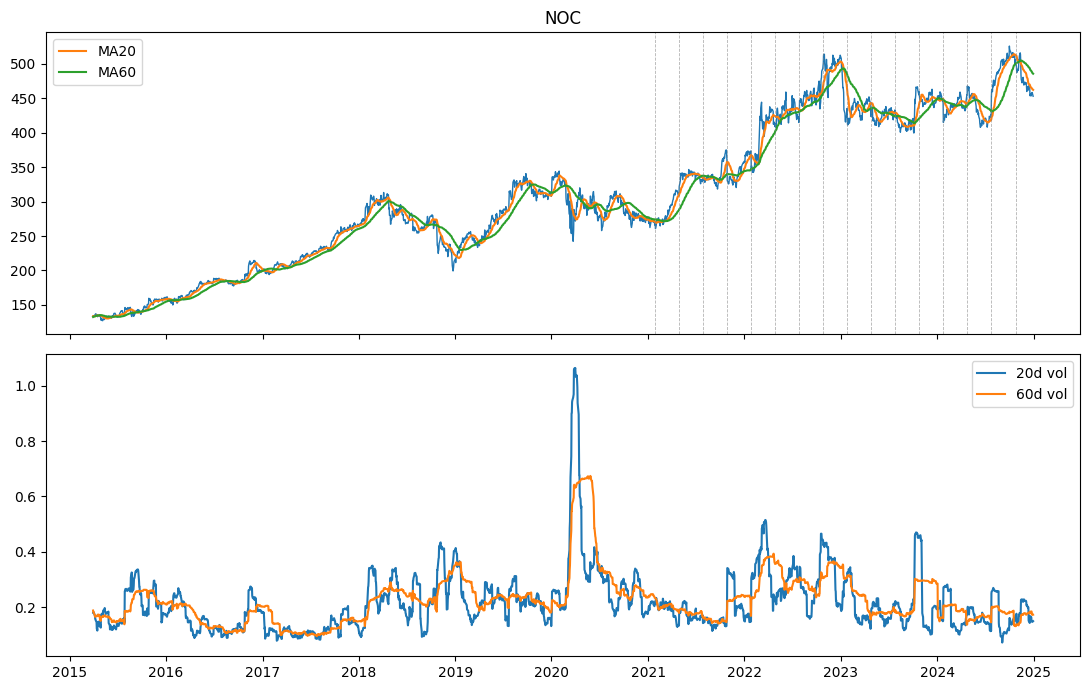

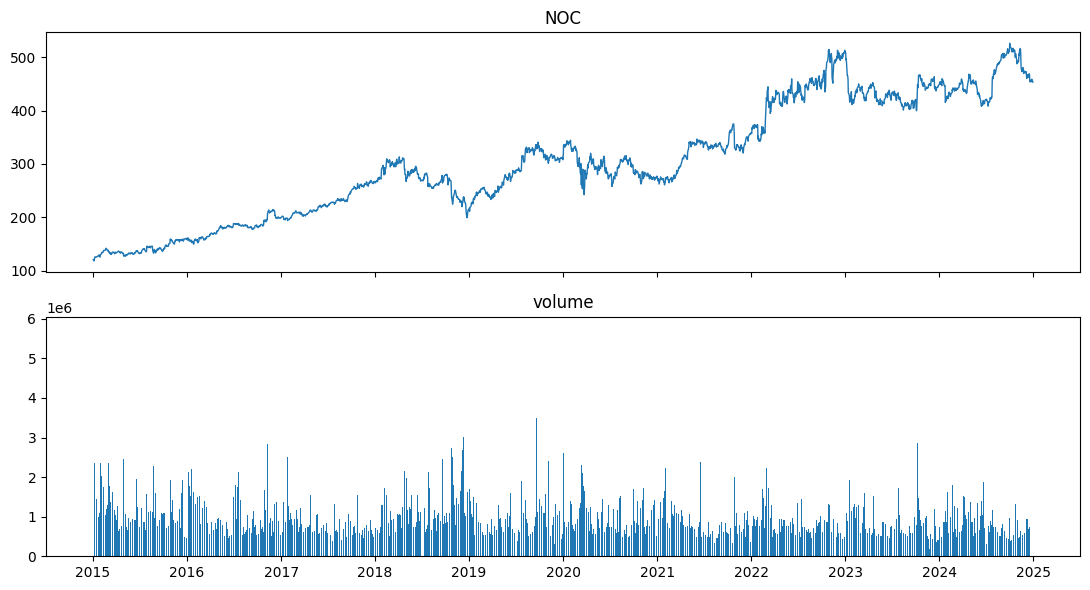

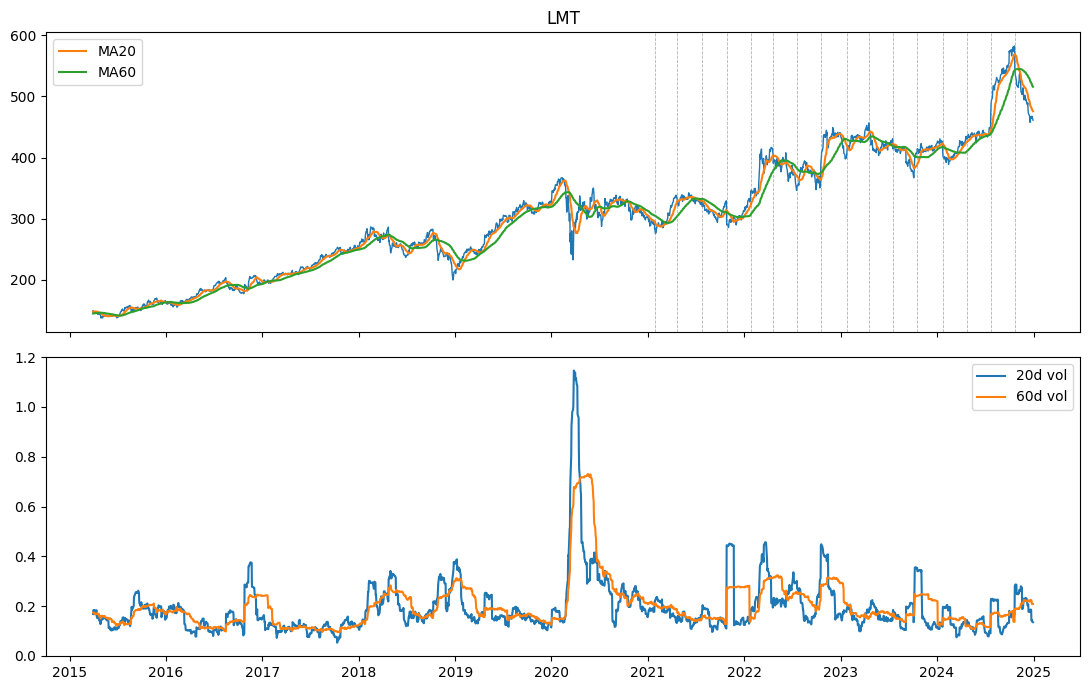

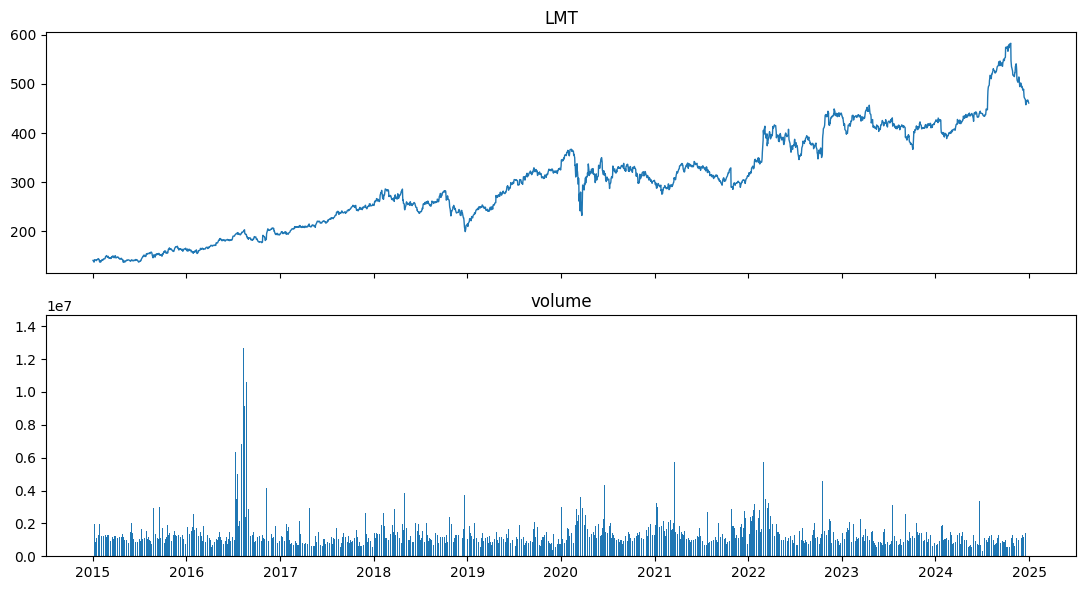

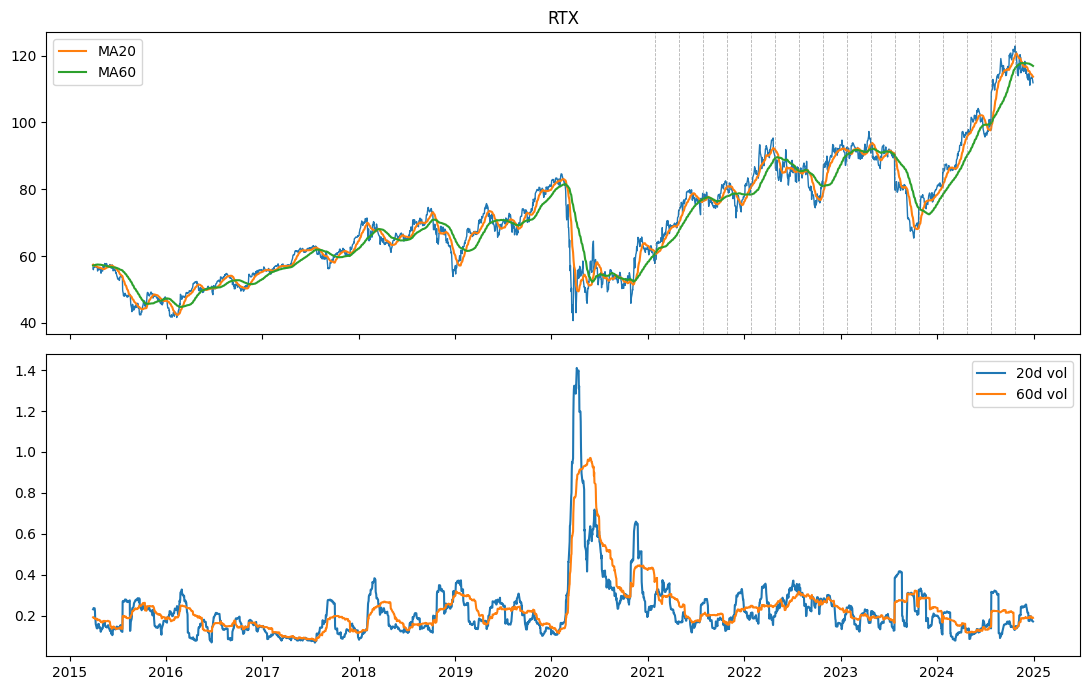

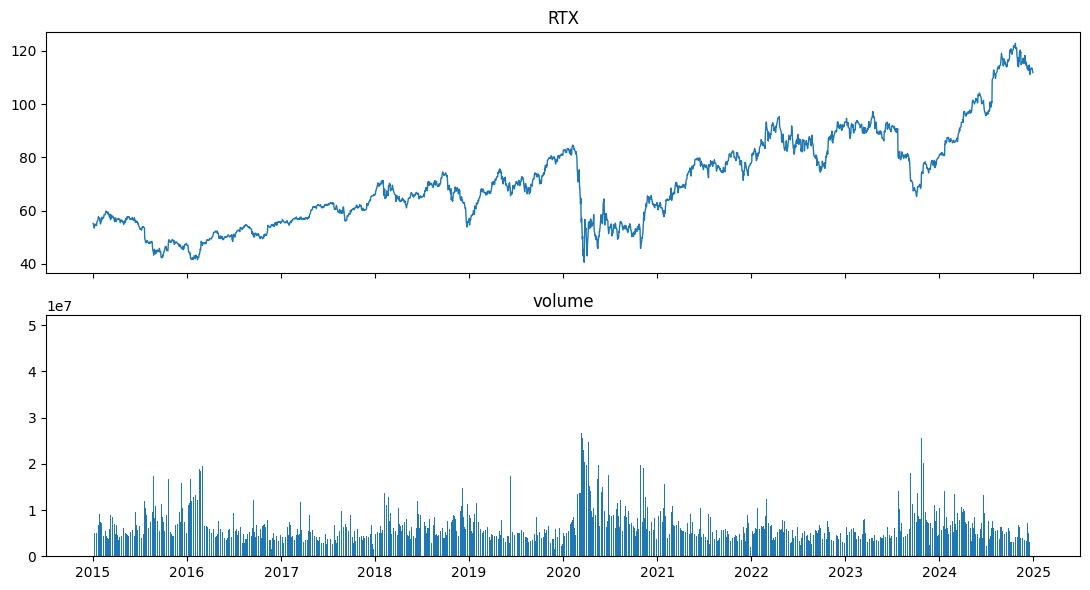

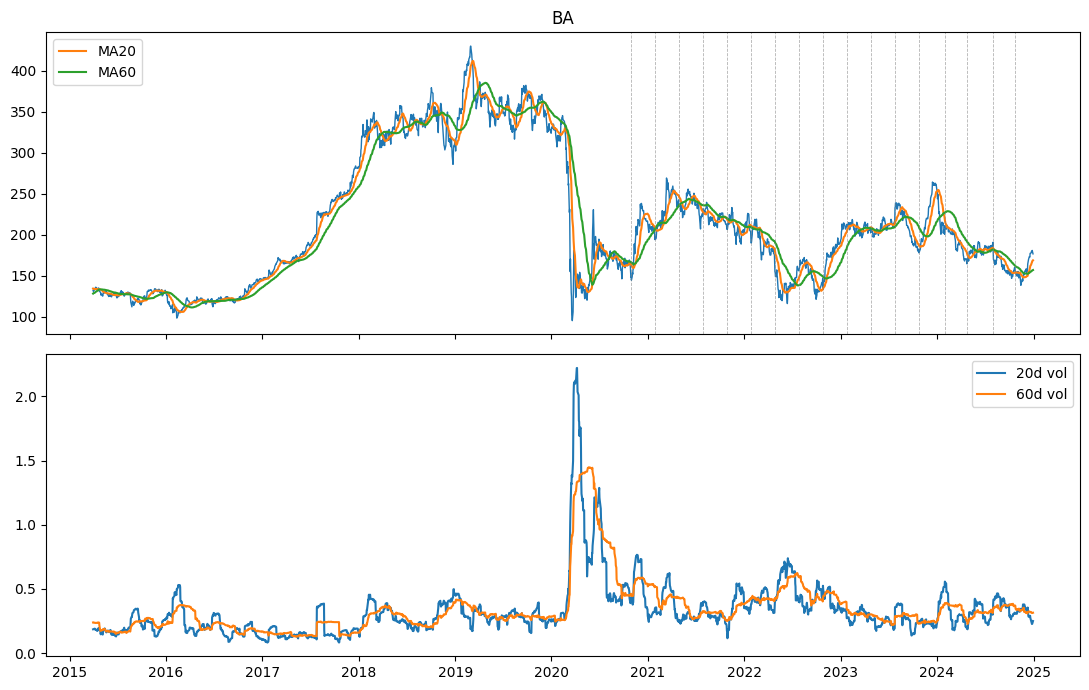

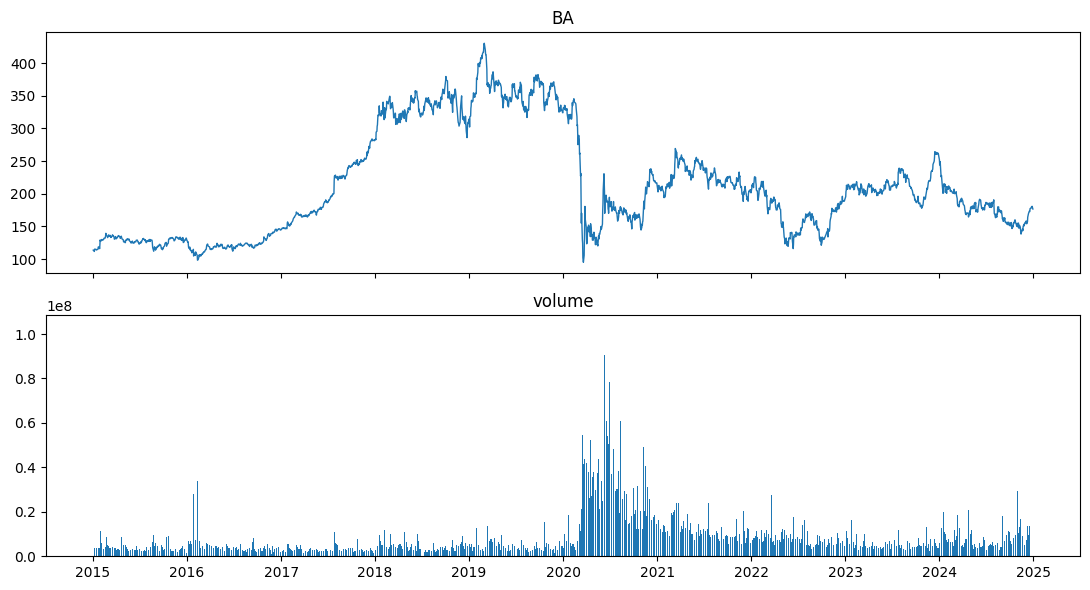

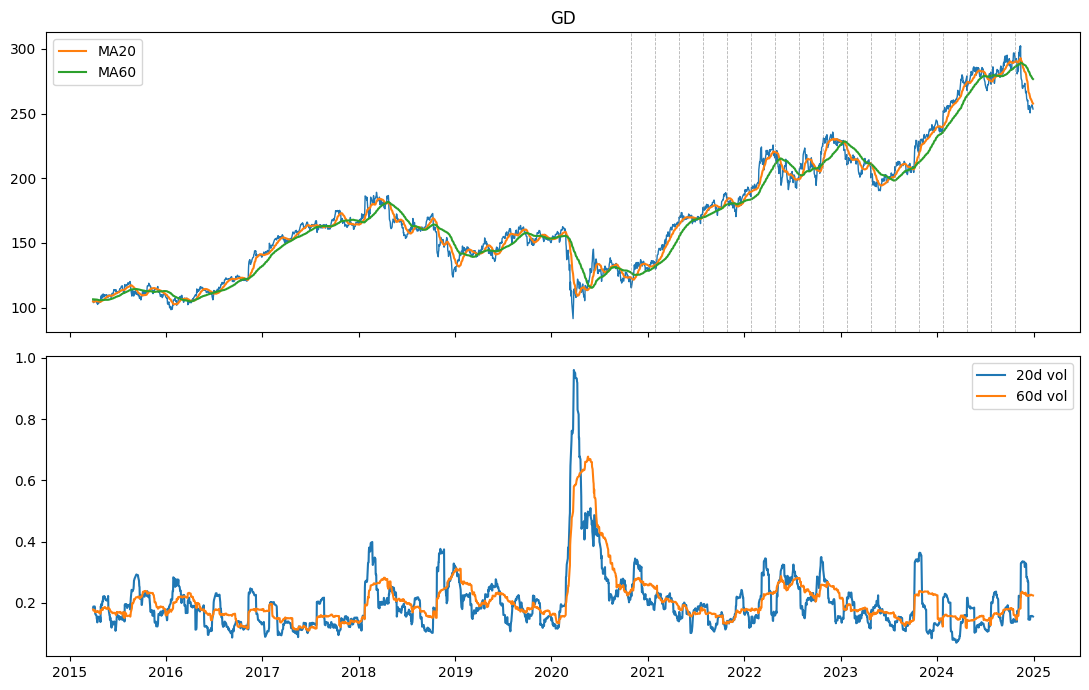

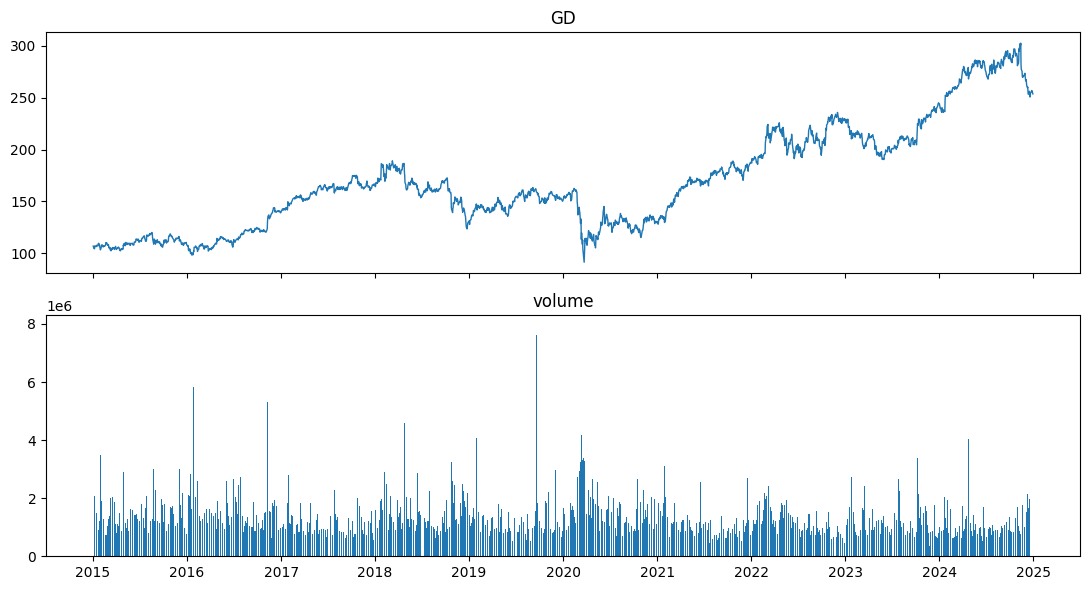

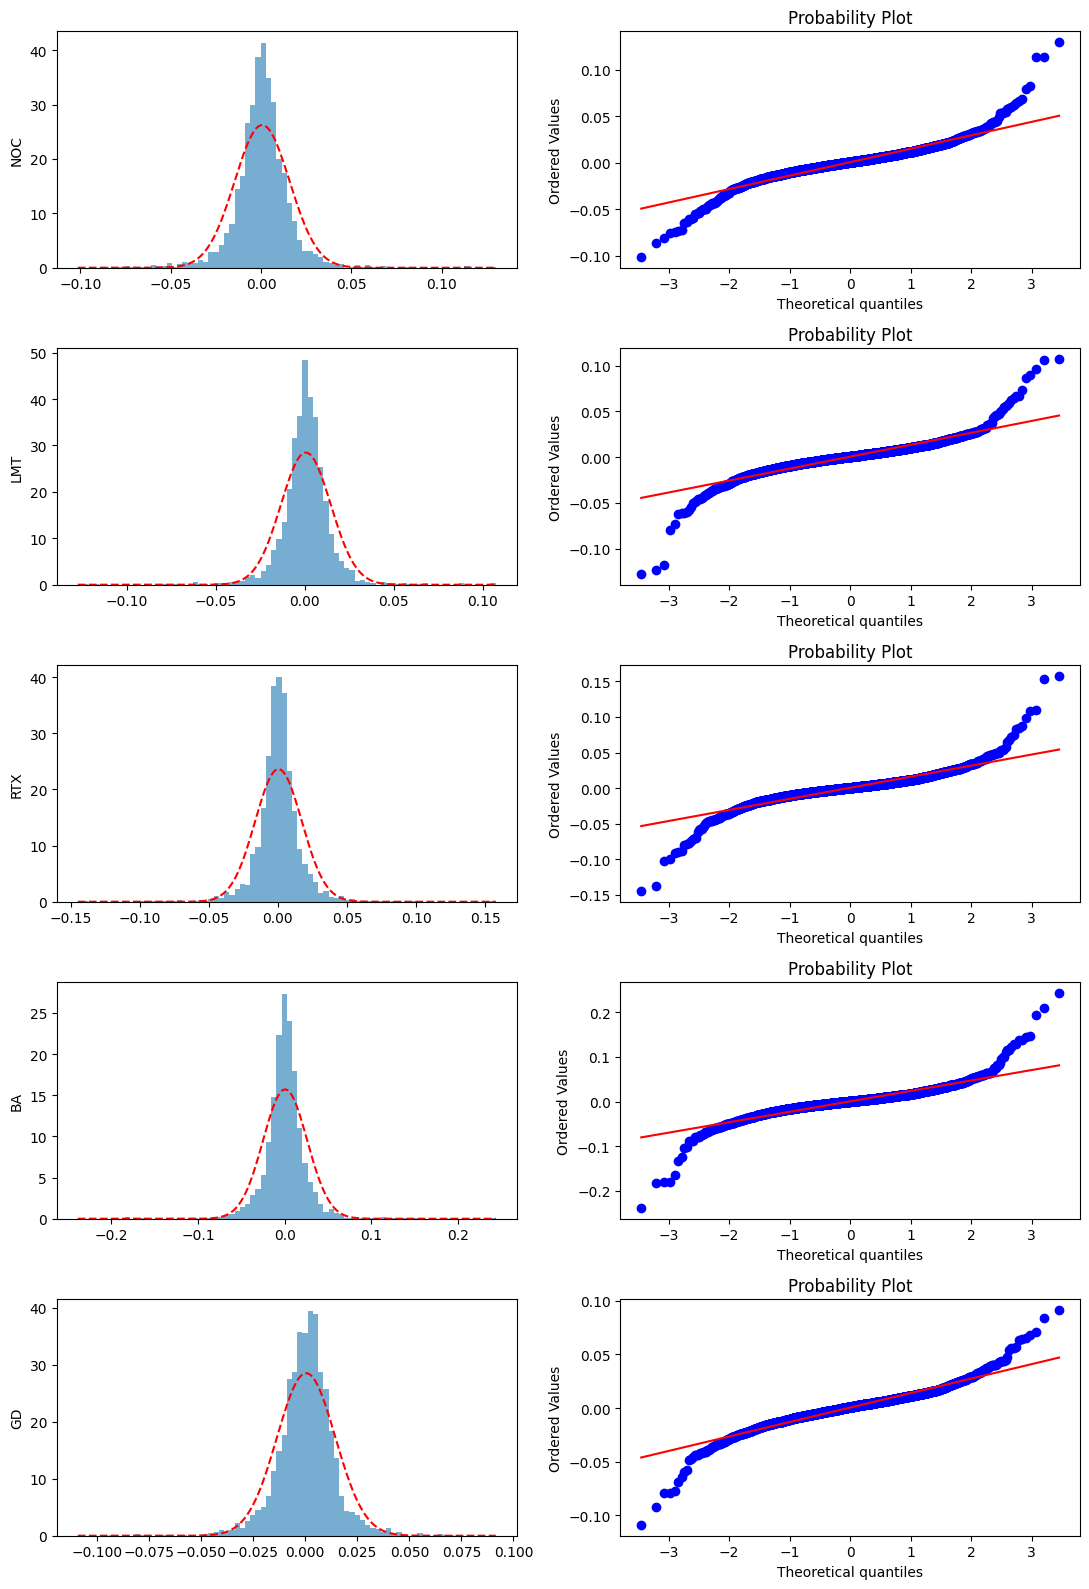

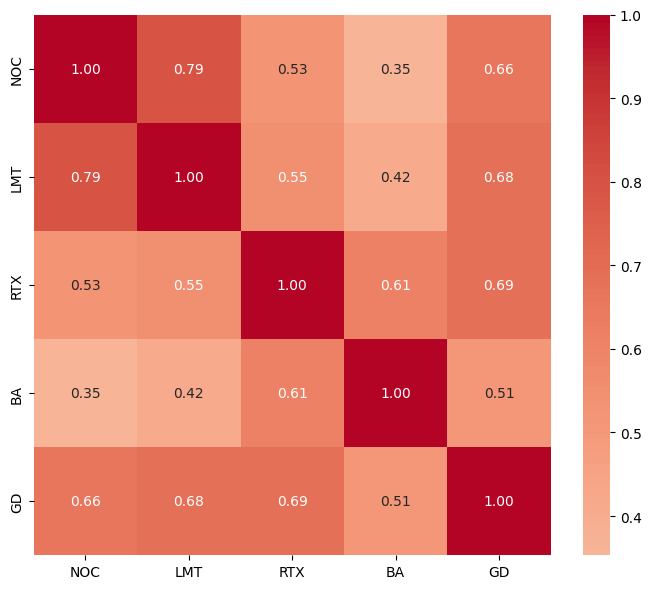

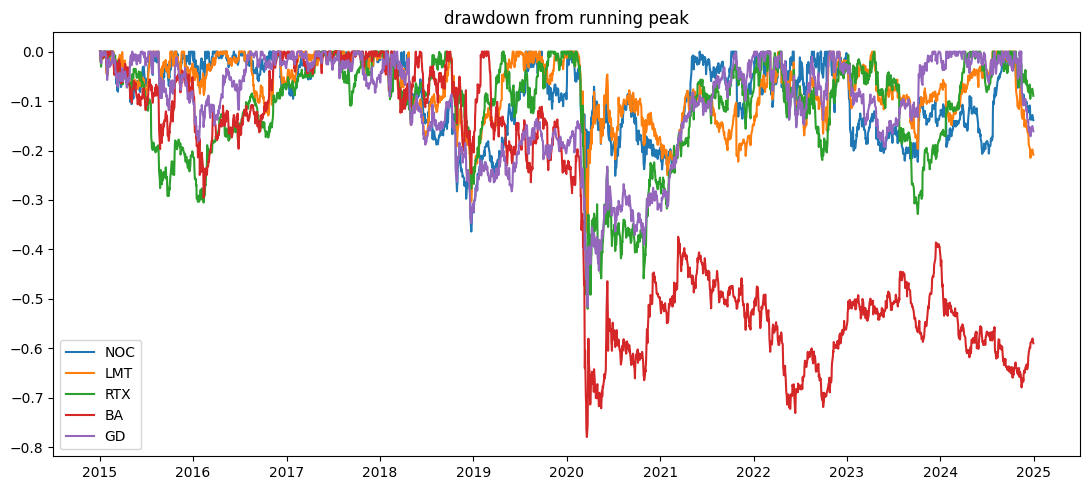

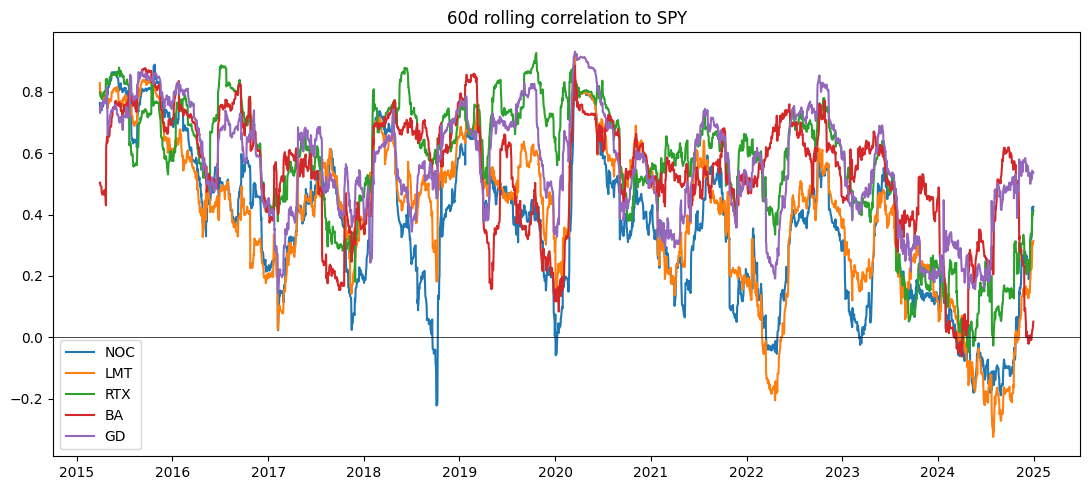

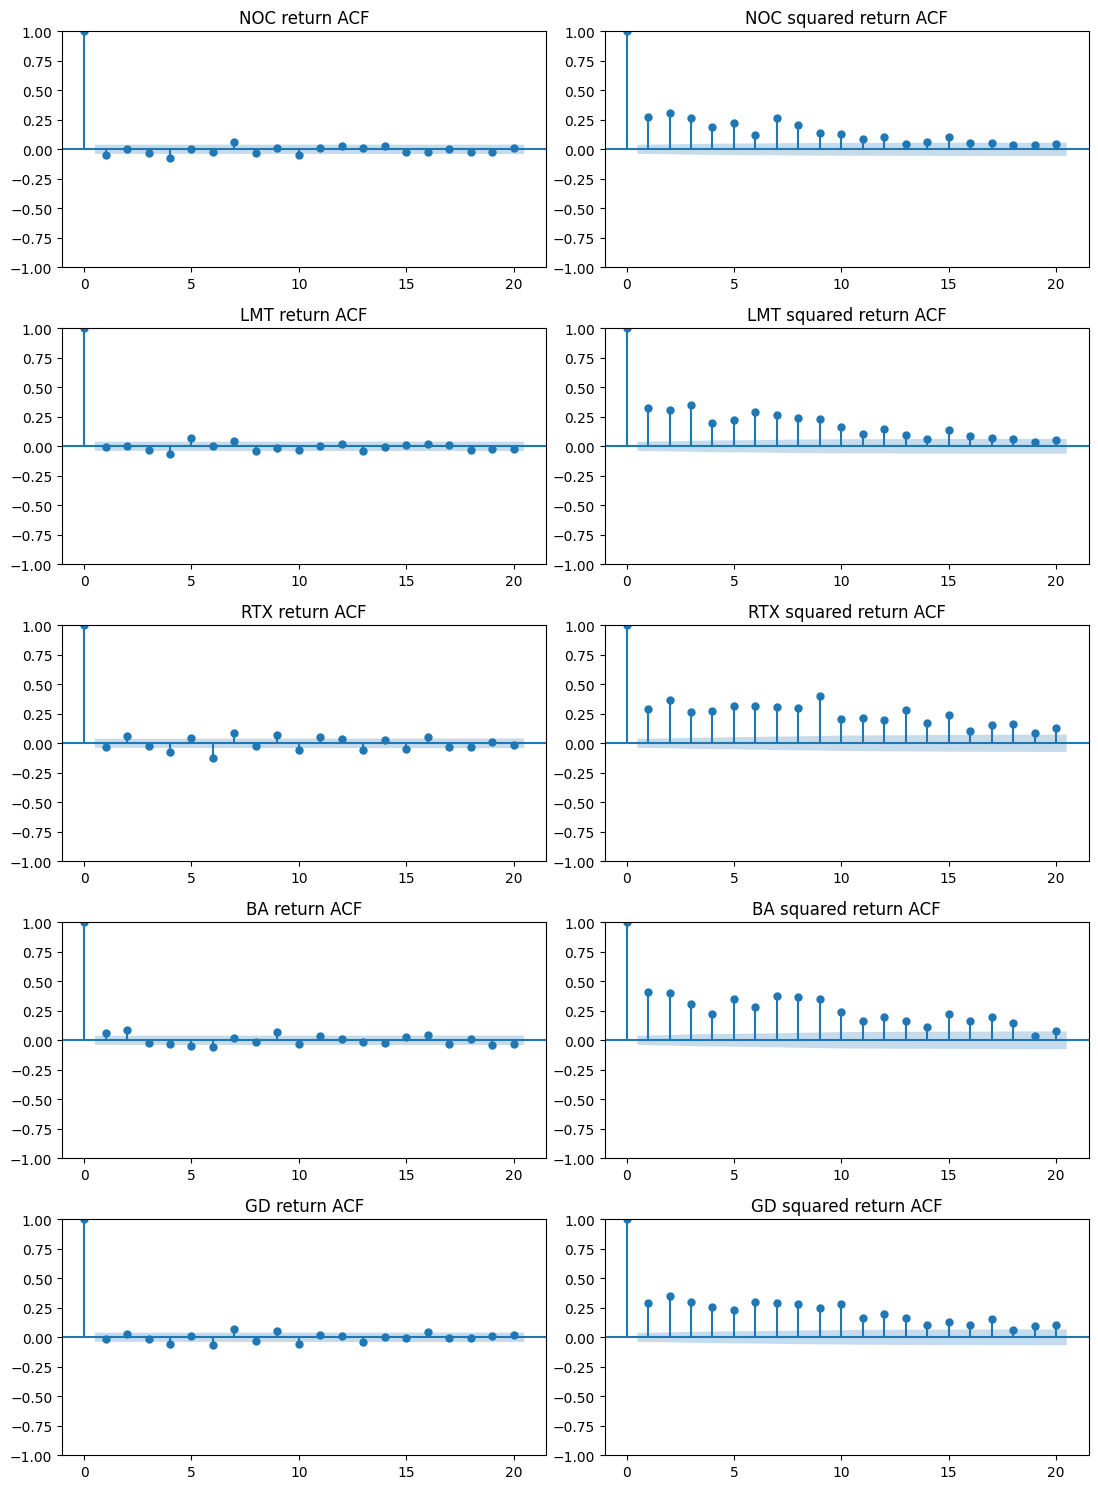

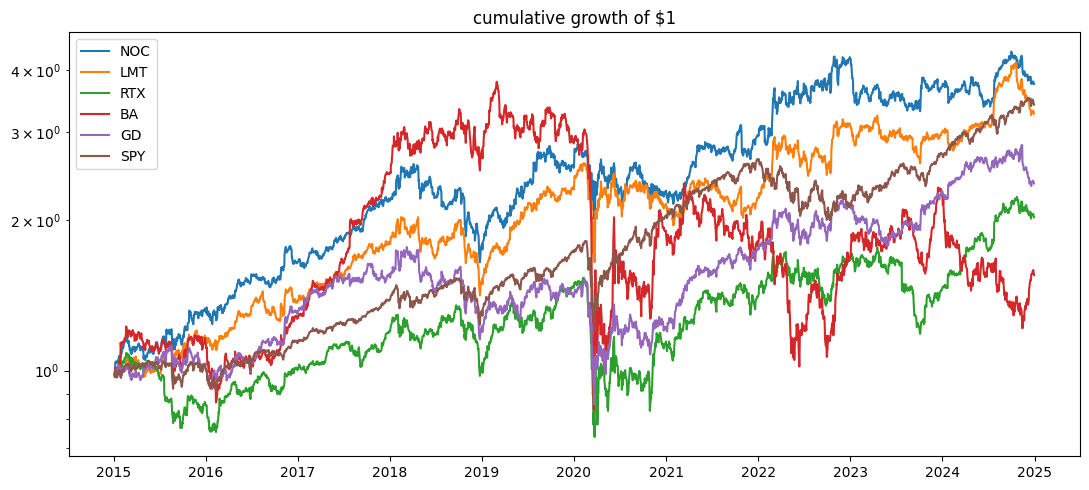

In [40]:
rc=rolling_corr_to_bench(returns, tickers, benchmark)
cum=cumulative_returns(returns, tickers + [benchmark])

rolling=rolling_stats(closes, returns, windows, tickers)
for t in tickers:
    plot_price_vol_earnings(rolling, t, windows, earnings)
    plot_volume(volumes, closes, t)

plot_distributions(returns, tickers)
plot_corr(returns, tickers)
plot_drawdowns(dd_curves, tickers)
plot_rolling_corr(rc, tickers)
plot_acf_grid(returns, tickers)
plot_cumulative(cum, tickers + [benchmark])
plot_vix_overlay(vix, rolling, tickers)